# Regional projection setup

Defines the spatial units of the regional projection analysis and prepares the cached regional means used by the indicator notebooks:

* the **Pacific EEZs** (`data/regional/Pacific_EEZs`), one mean per country, and the mean over **all the EEZs together** (`All Pacific EEZs`), which summarises every non-biochemical indicator (air temperature, rainfall, SST, marine heatwaves); sea level uses the mean over the whole Pacific window;
* four **ocean regions** (dashed boxes), used **only for the biochemical indicators** (pH, aragonite, salinity): North Pacific Subtropical Gyre, Equatorial Upwelling, Western Equatorial Pacific and South Pacific Subtropical Gyre. Their limits are set in `REGION_BOXES` in `functions/projections_regional.py`.

```{glue:figure} regions_fig
:scale: 60%
:align: center
```

**Figure. Pacific EEZs and the four ocean regions (biochemical indicators only).**

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ, all-EEZ and ocean-region means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../indicators_setup")
sys.path.append("../../../functions")
import projections as prj
import projections_regional as reg

,Region,Longitude,Latitude
0,North Pacific Subtropical Gyre,125–245°E,10–30°
1,Equatorial Upwelling,165–245°E,-5–5°
2,Western Equatorial Pacific,125–165°E,-15–5°
3,South Pacific Subtropical Gyre,190–245°E,-35–-15°


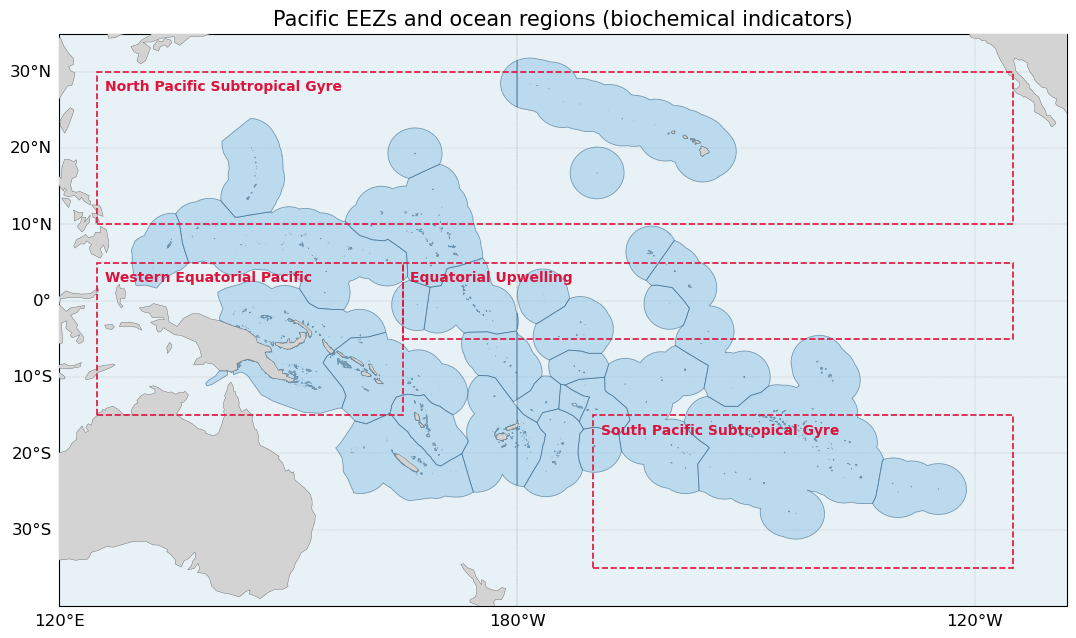

In [3]:
eez = reg.load_eez()
fig, ax = reg.plot_regions_map(eez)
fig_dir = Path("../../../outputs/figures/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
reg.save_figure(fig, fig_dir, "regions_map")
glue("regions_fig", fig, display=False)

pd.DataFrame([{"Region": name, "Longitude": f"{x0}–{x1}°E", "Latitude": f"{y0}–{y1}°"}
              for name, (x0, x1, y0, y1) in reg.REGION_BOXES.items()])

## Global warming levels

The regional analysis uses the warming-level years of the national projections ([`../National/00_warming_levels.ipynb`](../National/00_warming_levels.ipynb)).

In [4]:
scenario_info = prj.load_warming_levels(list(prj.SCENARIOS))
pd.DataFrame({sc.upper(): {f"+{wl}°C": str(v["year"])[:4] if prj._reached(v["year"]) else "—" for wl, v in levels.items()}
              for sc, levels in scenario_info.items()}).T

,+1.5°C,+2.0°C,+2.5°C,+3.0°C
SSP126,2032,—,—,—
SSP245,2030,2052,2079,—
SSP370,2030,2046,2061,2075
SSP585,2027,2041,2053,2064


## Regional means

Average every model, scenario and year over each EEZ, all the EEZs together and each ocean region and cache the result in `data/projections/regional/`. This is the slow step (the monthly SST and rainfall files are read in full once); the indicator notebooks reuse the cache. Set `overwrite=True` to recompute.

In [5]:
overwrite = False
for variable in prj.CSIRO_VARIABLES:
    ds = reg.extract_regional_means(variable, eez, list(prj.SCENARIOS), overwrite=overwrite)
    print(f"{variable:15s} {dict(ds.sizes)}")
ds = reg.extract_atlas_ph_regional(eez, overwrite=overwrite)
print(f"{'ph (Atlas)':15s} {dict(ds.sizes)}")
ds = reg.extract_atlas_ph_grid(overwrite=overwrite)
print(f"{'ph grid (Atlas)':15s} {dict(ds.sizes)}")
ds = reg.extract_mhw_regional(eez, overwrite=overwrite)
print(f"{'mhw':15s} {dict(ds.sizes)}")
for variable in prj.OCADS_FILE_NAMES:
    ds = reg.extract_ocads_regional(variable, eez, list(prj.SCENARIOS), overwrite=overwrite)
    print(f"{variable + ' (OCADS)':15s} {dict(ds.sizes)}")
for variable in ("pHT", "aragonite", "salinity"):
    ds = reg.extract_ocads_models_regional(variable, eez, list(prj.SCENARIOS), overwrite=overwrite)
    print(f"{variable + ' (ESMs)':15s} {dict(ds.sizes)}")

tas             {'scenario': 4, 'model': 38, 'time': 86, 'region': 34}
tasmin          {'scenario': 4, 'model': 27, 'time': 86, 'region': 34}
tasmax          {'scenario': 4, 'model': 27, 'time': 86, 'region': 34}
warmdays        {'scenario': 4, 'model': 27, 'time': 86, 'region': 34}
coldnights      {'scenario': 4, 'model': 26, 'time': 86, 'region': 34}
pr              {'scenario': 4, 'model': 36, 'time': 85, 'region': 34}
yearmax         {'scenario': 4, 'model': 30, 'time': 85, 'region': 34}
dry_days        {'scenario': 4, 'model': 30, 'time': 85, 'region': 34}
heavyraindays   {'scenario': 4, 'model': 30, 'time': 85, 'region': 34}
tos             {'scenario': 4, 'model': 35, 'time': 85, 'region': 34}
ph (Atlas)      {'scenario': 3, 'model': 10, 'time': 86, 'region': 34}
ph grid (Atlas) {'scenario': 3, 'model': 10, 'time': 86, 'lat': 75, 'lon': 132}
mhw             {'scenario': 2, 'model': 18, 'time': 119, 'cat': 4, 'region': 34}
pHT (OCADS)     {'scenario': 4, 'time': 9, 'region': 34}


pHT (ESMs)      {'model': 14, 'time': 9, 'region': 34, 'scenario': 4}
aragonite (ESMs) {'scenario': 4, 'model': 14, 'time': 9, 'region': 34}
salinity (ESMs) {'scenario': 4, 'model': 14, 'time': 9, 'region': 34}
